# Coherent noise on a distance-3 surface code

Clifford simulators run Pauli noise only. Real gate errors are often **coherent**: small, systematic
over-rotations whose amplitudes can add up across gates before a measurement collapses
them. Decoder studies usually replace them by their **Pauli twirl**, which has the same
per-gate infidelity but no coherence.

This notebook simulates the coherent noise itself, with Maestro, on a Deltakit d=3 rotated
surface code memory experiment, and measures how far its Pauli twirl is from it.

| Run | Maestro simulator |
|---|---|
| Pauli noise (SI1000, and the twirl) | stabilizer, sampled on Pauli frames |
| Coherent noise | matrix product state (MPS) |

Everything is decoded with PyMatching against the twirl's detector error model, so the
decoder is the same in every comparison.

**Runtime:** about 40 seconds on a 12-core laptop, almost all of it the coherent sampling.

In [1]:
# Deltakit must be imported before pymatching: with pymatching 2.4 loaded
# first, Deltakit's circuit builders fail with "Caught an unknown exception!".
from deltakit.circuit.gates import PauliBasis
from deltakit.explorer.codes import RotatedPlanarCode, css_code_memory_circuit
from deltakit.explorer.qpu import QPU, SI1000Noise

import time

import maestro
import matplotlib.pyplot as plt
import numpy as np
import pymatching
import stim

from deltakit_maestro import MaestroBackend, to_stim

DISTANCE = 3
ROUNDS = 3
P_VALUES = [0.003, 0.005, 0.0075, 0.01]   # SI1000 strength p
CHI = 32                                  # MPS bond dimension for the sweep
COHERENT_SHOTS = 800                      # MPS, ~60 ms a shot per core
PAULI_SHOTS = 200_000                     # Pauli frames are cheap, so their error bars are tiny
SEED = 1

In [2]:
# Colors follow the noise model through every figure; each also has its own marker.
COLORS = {'SI1000': '#1baf7a', 'twirl': '#eb6834', 'coherent': '#2a78d6'}
MARKERS = {'SI1000': '^', 'twirl': 's', 'coherent': 'o'}
LABELS = {'SI1000': 'SI1000 Pauli (stabilizer)', 'twirl': 'Pauli twirl (stabilizer)',
          'coherent': 'Coherent (MPS)'}
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3de', '#fcfcfb'

plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'savefig.facecolor': SURFACE, 'font.size': 10,
    'axes.edgecolor': INK_2, 'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'legend.frameon': False,
    'lines.linewidth': 2, 'lines.markersize': 7, 'errorbar.capsize': 0,
})


def memory_circuit(p: float) -> stim.Circuit:
    # d=3 rotated surface code, Z-basis memory, SI1000(p) noise.
    code = RotatedPlanarCode(width=DISTANCE, height=DISTANCE)
    circuit = css_code_memory_circuit(code, num_rounds=ROUNDS, logical_basis=PauliBasis.Z)
    return to_stim(QPU(circuit.qubits, noise_model=SI1000Noise(p=p)).compile_and_add_noise_to_circuit(circuit))


def logical_error_rate(matcher, dets, obs):
    # Fraction of shots PyMatching gets wrong, with its binomial standard error.
    fails = np.any(matcher.decode_batch(dets) != obs, axis=1)
    rate = fails.mean()
    return rate, np.sqrt(rate * (1 - rate) / len(fails))


def detection_rate(dets):
    # Mean detection-event rate, with its error from the spread between shots.
    per_shot = dets.mean(axis=1)
    return per_shot.mean(), per_shot.std(ddof=1) / np.sqrt(len(per_shot))


def label_end(ax, x, y, text, color, dy=0):
    # Direct label just right of a line's last point, in ink, with a color key mark;
    # dy (points) separates labels whose lines end close together.
    ax.annotate(f'■ {text}', (x, y), xytext=(8, dy), textcoords='offset points',
                va='center', fontsize=9, color=INK)
    ax.annotate('■', (x, y), xytext=(8, dy), textcoords='offset points',
                va='center', fontsize=9, color=color)

## 1. The circuit, and which simulator runs what

`MaestroBackend` decides per run. A run with Pauli noise only goes to Maestro's stabilizer,
which samples it exactly on Pauli frames; coherent noise needs a matrix product state.

In [3]:
backend = MaestroBackend(max_bond_dimension=CHI)
circuit = memory_circuit(0.01)
print(f'{circuit.num_qubits} qubits, {ROUNDS} rounds, {circuit.num_detectors} detectors, '
      f'{circuit.num_observables} logical observable')
for noise_type in ('pauli', 'coherent'):
    simulation_type = backend.config_for(noise_type).simulation_type
    detail = f', chi={CHI}' if simulation_type == maestro.SimulationType.MatrixProductState else ''
    print(f'  {noise_type:<9} -> {simulation_type.name}{detail}')

17 qubits, 3 rounds, 24 detectors, 1 logical observable
  pauli     -> Stabilizer
  coherent  -> MatrixProductState, chi=32


## 2. The noise being compared

- **SI1000(p):** Deltakit's superconducting noise model. All Pauli.
- **Coherent:** each gate's depolarizing is replaced by a rotation of
  ε = 2·arcsin√p about a body diagonal of the Bloch sphere, after every gate, on every
  qubit it touches. The signs are drawn once per qubit per shot, so a qubit's rotations
  add coherently between measurements. SI1000's idle, reset and readout noise is kept.
- **Pauli twirl of the coherent noise:** each rotation replaced by `DEPOLARIZE1(p)`. That
  is exactly its twirl, with the same infidelity and no coherence.

The comparison that isolates coherence is **coherent against its twirl**. SI1000 is there
for context only. The coherent layer has strength p after every gate, where SI1000 has
p/10 after single-qubit gates, so it is noisier than SI1000 before any coherence.

## 3. Is χ = 32 enough?

The MPS truncates the state to bond dimension χ, and truncation shows up as extra detection
events, in the same direction as the coherent effect. So χ is checked two ways:

1. **Noiseless check.** With no noise every detector must stay silent, so any detection
   event is truncation error.
2. **Convergence.** Coherent noise needs more χ than a noiseless run, so χ is raised until
   the detection-event rate stops changing.

In [4]:
MPS = maestro.SimulationType.MatrixProductState
noiseless_chis, noiseless_failed = [4, 8, 16, 32], []
for chi in noiseless_chis:
    dets = MaestroBackend(simulation_type=MPS, max_bond_dimension=chi).simulate(
        circuit, 200, 'none', seed=SEED).detection_events
    noiseless_failed.append(dets.any(axis=1).mean())

coherent_chis, coherent_rates, coherent_ms = [4, 8, 16, 32, 64], [], []
for chi in coherent_chis:
    t0 = time.time()
    dets = MaestroBackend(max_bond_dimension=chi).simulate(circuit, 400, 'coherent', seed=SEED).detection_events
    coherent_ms.append((time.time() - t0) / 400 * 1e3)
    coherent_rates.append(detection_rate(dets))

twirl_reference = backend.simulate(backend.twirled_circuit(circuit, 'coherent'), PAULI_SHOTS,
                                   seed=SEED).detection_events.mean()

print(f"{'chi':>4} | noiseless shots with a detection | coherent detection-event rate | ms/shot")
for i, chi in enumerate(coherent_chis):
    failed = f'{noiseless_failed[i]:>10.1%}' if i < len(noiseless_chis) else f"{'-':>10}"
    rate, err = coherent_rates[i]
    print(f'{chi:>4} | {failed:>33} | {rate:>19.4f} ± {err:.4f} | {coherent_ms[i]:>7.1f}')
print(f'Pauli twirl of the same noise: {twirl_reference:.4f}')

 chi | noiseless shots with a detection | coherent detection-event rate | ms/shot
   4 |                             98.5% |              0.3109 ± 0.0050 |     2.1
   8 |                              0.0% |              0.2938 ± 0.0052 |     3.1
  16 |                              0.0% |              0.2718 ± 0.0053 |     5.3
  32 |                              0.0% |              0.2625 ± 0.0054 |     6.2
  64 |                                 - |              0.2625 ± 0.0054 |     6.3
Pauli twirl of the same noise: 0.2362


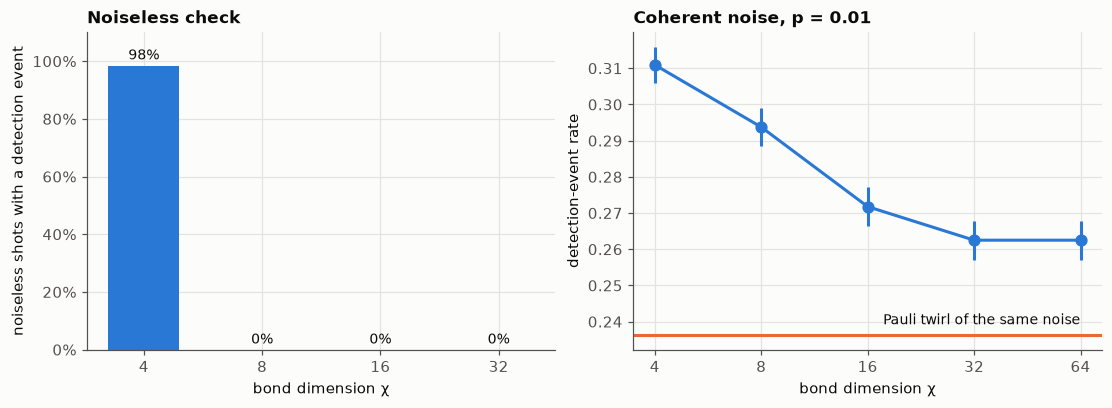

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')

left.bar([str(c) for c in noiseless_chis], noiseless_failed, width=0.6,
         color=COLORS['coherent'])
for i, f in enumerate(noiseless_failed):
    left.annotate(f'{f:.0%}', (i, f), xytext=(0, 4), textcoords='offset points',
                  ha='center', fontsize=9, color=INK)
left.set(title='Noiseless check', xlabel='bond dimension χ',
         ylabel='noiseless shots with a detection event', ylim=(0, 1.1))
left.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

rates, errs = np.array(coherent_rates).T
right.errorbar(coherent_chis, rates, yerr=errs, color=COLORS['coherent'],
               marker=MARKERS['coherent'], label=LABELS['coherent'])
right.axhline(twirl_reference, color=COLORS['twirl'], linewidth=2)
right.annotate('Pauli twirl of the same noise', (coherent_chis[-1], twirl_reference),
               xytext=(0, 5), textcoords='offset points', ha='right', va='bottom', fontsize=9, color=INK)
right.set(title=f'Coherent noise, p = 0.01', xlabel='bond dimension χ',
          ylabel='detection-event rate', xscale='log', xticks=coherent_chis)
right.set_xticklabels([str(c) for c in coherent_chis])
right.minorticks_off()
plt.show()

The noiseless circuit is exact from χ = 8, but the coherent rate keeps falling until
χ = 32 and then holds. At small χ, truncation adds about as many detection events as
coherence does. χ = 32 is used from here on.

## 4. Coherent noise against its twirl

For each p: Maestro samples the coherent noise on an MPS and the twirl and SI1000 on its
stabilizer, and one
PyMatching decoder, built from the twirl's detector error model, decodes all three.

In [6]:
results, samples = [], {}
for p in P_VALUES:
    noisy = memory_circuit(p)
    t0 = time.time()
    sampler = backend.compile_sampler(noisy, 'coherent', seed=SEED)
    coherent = sampler.sample_detection_events(COHERENT_SHOTS)
    seconds = time.time() - t0
    matcher = pymatching.Matching.from_detector_error_model(sampler.task.detector_error_model)
    twirl = backend.compile_sampler(backend.twirled_circuit(noisy, 'coherent'), seed=SEED
                                    ).sample_detection_events(PAULI_SHOTS)
    si1000 = backend.compile_sampler(noisy, seed=SEED).sample_detection_events(PAULI_SHOTS)
    samples[p] = {'coherent': coherent, 'twirl': twirl, 'circuit': noisy}
    results.append({'p': p, 'seconds': seconds,
                    **{f'lep_{k}': logical_error_rate(matcher, *v)
                       for k, v in (('SI1000', si1000), ('twirl', twirl), ('coherent', coherent))},
                    **{f'det_{k}': detection_rate(v[0])
                       for k, v in (('SI1000', si1000), ('twirl', twirl), ('coherent', coherent))}})

print(f"{'p':>7} | {'SI1000 LEP':>15} | {'twirl LEP':>15} | {'coherent LEP':>15} | "
      f"{'LEP ratio':>9} | {'det. ratio':>10} | coherent")
for r in results:
    lep_ratio = r['lep_coherent'][0] / r['lep_twirl'][0]
    det_ratio = r['det_coherent'][0] / r['det_twirl'][0]
    cells = ' | '.join(f"{r[f'lep_{k}'][0]:.4f} ± {r[f'lep_{k}'][1]:.4f}"
                       for k in ('SI1000', 'twirl', 'coherent'))
    print(f"{r['p']:>7.4f} | {cells} | {lep_ratio:>9.2f} | {det_ratio:>10.2f} | {r['seconds']:>5.0f} s")

      p |      SI1000 LEP |       twirl LEP |    coherent LEP | LEP ratio | det. ratio | coherent
 0.0030 | 0.0284 ± 0.0004 | 0.0359 ± 0.0004 | 0.0475 ± 0.0075 |      1.32 |       1.13 |     4 s
 0.0050 | 0.0709 ± 0.0006 | 0.0864 ± 0.0006 | 0.1050 ± 0.0108 |      1.22 |       1.16 |     5 s
 0.0075 | 0.1340 ± 0.0008 | 0.1604 ± 0.0008 | 0.1900 ± 0.0139 |      1.18 |       1.15 |     5 s
 0.0100 | 0.1992 ± 0.0009 | 0.2325 ± 0.0009 | 0.2675 ± 0.0157 |      1.15 |       1.11 |     5 s


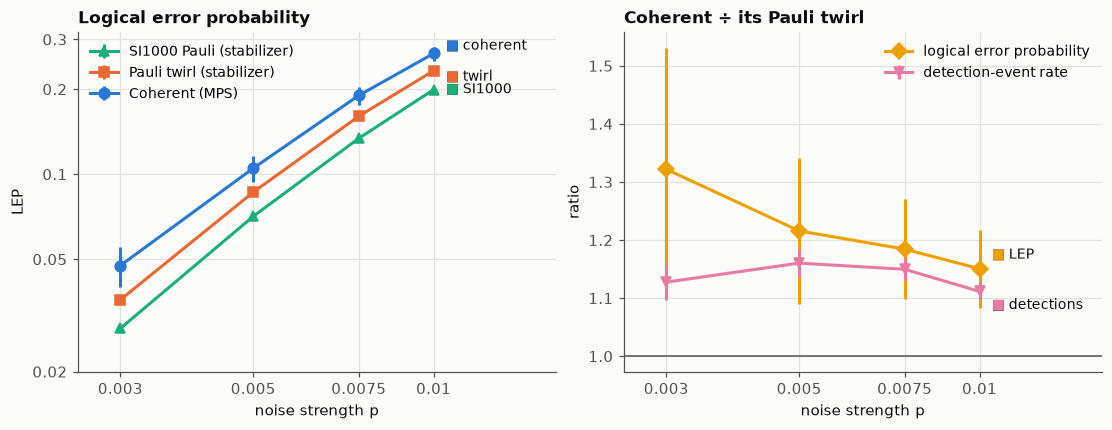

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
ps = np.array(P_VALUES)

for key in ('SI1000', 'twirl', 'coherent'):
    rate, err = np.array([r[f'lep_{key}'] for r in results]).T
    left.errorbar(ps, rate, yerr=err, color=COLORS[key], marker=MARKERS[key], label=LABELS[key])
    label_end(left, ps[-1], rate[-1], key, COLORS[key], dy={'coherent': 5, 'twirl': -4}.get(key, 0))
left.set(title='Logical error probability', xlabel='noise strength p', ylabel='LEP',
         xscale='log', yscale='log', xlim=(ps[0] * 0.85, ps[-1] * 1.6))
lep_ticks = [0.02, 0.05, 0.1, 0.2, 0.3]
left.set_yticks(lep_ticks, [f'{t:g}' for t in lep_ticks])
left.set_xticks(ps, [f'{p:g}' for p in ps])
left.minorticks_off()
left.legend(loc='upper left', fontsize=9)

for key, what in (('lep', 'logical error probability'), ('det', 'detection-event rate')):
    ratio = np.array([r[f'{key}_coherent'][0] / r[f'{key}_twirl'][0] for r in results])
    # Propagated standard error of the ratio (the twirl's is negligible).
    err = ratio * np.array([r[f'{key}_coherent'][1] / r[f'{key}_coherent'][0] for r in results])
    color, marker = ('#eda100', 'D') if key == 'lep' else ('#e87ba4', 'v')
    right.errorbar(ps, ratio, yerr=err, color=color, marker=marker, label=what)
    label_end(right, ps[-1], ratio[-1], 'LEP' if key == 'lep' else 'detections', color,
              dy=9 if key == 'lep' else -9)
right.axhline(1, color=INK_2, linewidth=1)
right.set(title='Coherent ÷ its Pauli twirl', xlabel='noise strength p', ylabel='ratio',
          xscale='log', xlim=(ps[0] * 0.85, ps[-1] * 1.6))
right.set_xticks(ps, [f'{p:g}' for p in ps])
right.minorticks_off()
right.legend(loc='upper right', fontsize=9)
plt.show()

## 5. Where the extra detection events land

Using the p = 0.01 samples: the rate of every detector under coherent noise against the
same detector under the twirl, and how many detection events each shot has. The
coherent histogram ends where its 800 shots run out, near 10⁻³; the twirl has 200,000.

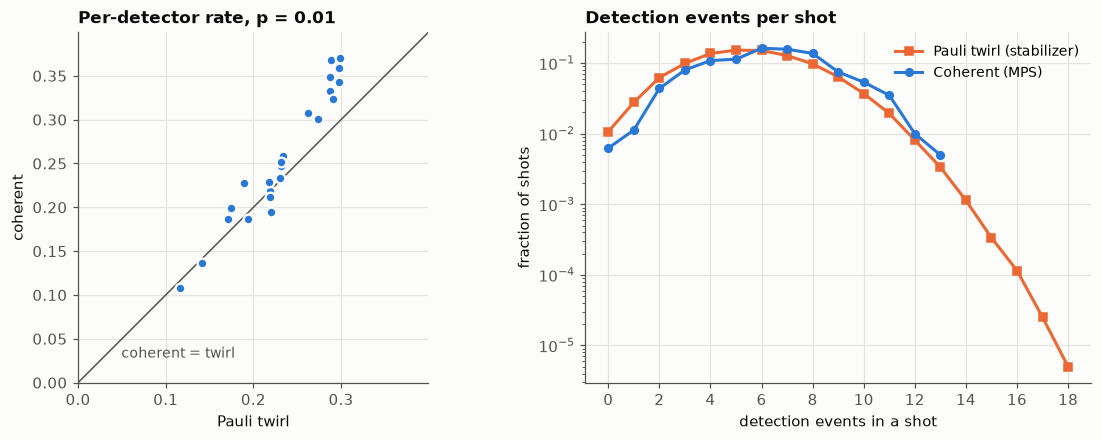

75% of the 24 detectors fire more often under coherent noise.
Mean detection events per shot: coherent 6.30, twirl 5.67.
  detectors at t=0: coherent 0.1675, twirl 0.1553
  detectors at t=1: coherent 0.2927, twirl 0.2594
  detectors at t=2: coherent 0.2887, twirl 0.2590
  detectors at t=3: coherent 0.2453, twirl 0.2253


In [8]:
p = P_VALUES[-1]
coherent_dets, twirl_dets = samples[p]['coherent'][0], samples[p]['twirl'][0]
coherent_by_detector, twirl_by_detector = coherent_dets.mean(axis=0), twirl_dets.mean(axis=0)
# Deltakit's circuit builder is not deterministic, so read the sampled circuit's own detectors.
rounds = np.array([coords[2] for coords in samples[p]['circuit'].get_detector_coordinates().values()])

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9), layout='constrained')

top = max(coherent_by_detector.max(), twirl_by_detector.max()) * 1.08
left.plot([0, top], [0, top], color=INK_2, linewidth=1)
left.annotate('coherent = twirl', (top * 0.08, top * 0.08), xytext=(10, -2),
              textcoords='offset points', fontsize=9, color=INK_2)
left.scatter(twirl_by_detector, coherent_by_detector, s=40, color=COLORS['coherent'],
             edgecolors=SURFACE, linewidths=1.5, zorder=3)
left.set(title=f'Per-detector rate, p = {p:g}', xlabel='Pauli twirl',
         ylabel='coherent', xlim=(0, top), ylim=(0, top), aspect='equal')

counts = np.arange(coherent_dets.shape[1] + 1)
for key, dets in (('twirl', twirl_dets), ('coherent', coherent_dets)):
    freq = np.bincount(dets.sum(axis=1), minlength=len(counts)) / len(dets)
    shown = freq > 0
    right.plot(counts[shown], freq[shown], color=COLORS[key], marker=MARKERS[key],
               markersize=5, label=LABELS[key])
right.set(title='Detection events per shot', xlabel='detection events in a shot',
          ylabel='fraction of shots', yscale='log')
right.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
right.legend(fontsize=9)
plt.show()

above = (coherent_by_detector > twirl_by_detector).mean()
mean_coherent = coherent_dets.sum(axis=1).mean()
mean_twirl = twirl_dets.sum(axis=1).mean()
print(f'{above:.0%} of the {len(coherent_by_detector)} detectors fire more often under coherent noise.')
print(f'Mean detection events per shot: coherent {mean_coherent:.2f}, twirl {mean_twirl:.2f}.')
for t in np.unique(rounds):
    sel = rounds == t
    print(f'  detectors at t={t:g}: coherent {coherent_by_detector[sel].mean():.4f}, '
          f'twirl {twirl_by_detector[sel].mean():.4f}')

## Takeaways

- **The twirl underestimates coherent noise at every p tested.** Coherent noise gives
  about 11–16% more detection events than its Pauli twirl, and a higher logical error
  probability at every point. The detection-event ratio is the sharper measure here; the
  LEP ratios carry wide error bars from 800 coherent shots per point.
- **The excess is spread across the code.** Most detectors fire more often under coherent
  noise, the mid-circuit rounds (t = 1, 2) most of all, and shots with no detection event
  at all become rarer.
- **χ has to be checked, not assumed.** The noiseless circuit is exact from χ = 8, but
  coherent noise needs χ = 32. At χ = 8, truncation adds more detection events than
  coherence itself does, so too small a χ would more than double the effect being measured.
- **The decoder is matched to the twirl,** so the extra coherent errors are decoded as if
  they were Pauli: the usual decoder mismatch this kind of study is after.
- **Limits.** The coherent strength is p after every gate, which over-counts SI1000's
  single-qubit noise, so compare coherent noise against its own twirl, not against SI1000.
  And d = 3 rotated is the practical case: unrotated and toric codes, and d = 5, need a far
  larger χ (see `example_bond_dimension.py` and the guide's [Bond dimension](https://qoroquantum.github.io/deltakit-maestro/guide/bond_dimension.html) page).